<a href="https://colab.research.google.com/github/prajwalms07/DAV_Lab_Programs/blob/main/4NI25CS141prg_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------              

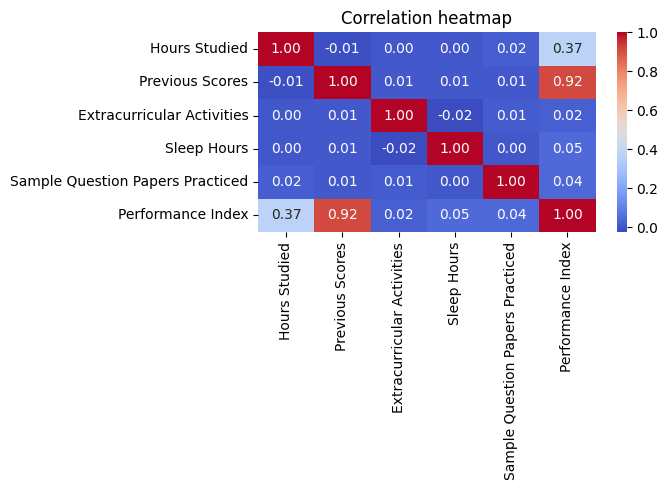

R2:  0.13160425385996788
RMSE:  17.93919001285204


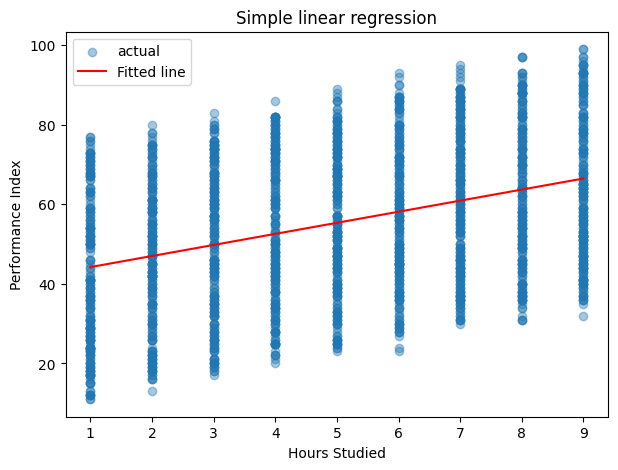

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# --------------------------------------------------
# 1. LOAD + INSPECT DATA
# --------------------------------------------------

df = pd.read_csv("/content/Student_Performance.csv")

print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())

# Convert the Yes/No column into 1/0 so the model can use it
df["Extracurricular Activities"] = df["Extracurricular Activities"].map(
    {"Yes": 1, "No": 0})

# --------------------------------------------------
# 2. QUICK EDA (Look before you model)
# --------------------------------------------------

plt.figure(figsize=(7, 5))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()

# --------------------------------------------------
# 3. SIMPLE LINEAR REGRESSION (1 feature -> 1 target)
# --------------------------------------------------

X_simple = df[["Hours Studied"]]  # 20 (DataFrame) because
y = df["Performance Index"]# 2D to target
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42)
simple_model = LinearRegression()
simple_model.fit(Xs_train, ys_train)
ys_pred = simple_model.predict(Xs_test)
print("R2: ",r2_score(ys_test, ys_pred))
print("RMSE: ",np.sqrt(mean_squared_error(ys_test, ys_pred)))

#plot the fitted line
plt.figure(figsize=(7, 5))
plt.scatter(Xs_test,ys_test,alpha=0.4,label = "actual")
plt.plot(Xs_test.sort_values("Hours Studied"),
         simple_model.predict(Xs_test.sort_values("Hours Studied")),
         color="red",
         label = "Fitted line")
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple linear regression")
plt.savefig("02_simple_fit.png")
plt.show()


In [12]:
# --------------------------------------------------
# 4. MULTIPLE LINEAR REGRESSION
# --------------------------------------------------
X = df.drop(columns="Performance Index")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

print("\n=== MULTIPLE LINEAR REGRESSION ===")
print("Intercept:", multi_model.intercept_)

for name, coef in zip(X.columns, multi_model.coef_):
    print(f"  {name:35s} {coef: .4f}")

y_pred = multi_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

n, p = X_test.shape

adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print("R2          :", r2)
print("Adjusted R2 :", adj_r2)
print("RMSE        :", rmse)




=== MULTIPLE LINEAR REGRESSION ===
Intercept: -33.92194621555638
  Hours Studied                        2.8525
  Previous Scores                      1.0170
  Extracurricular Activities           0.6086
  Sleep Hours                          0.4769
  Sample Question Papers Practiced     0.1918



                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:16:35   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:                         3.418e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const 

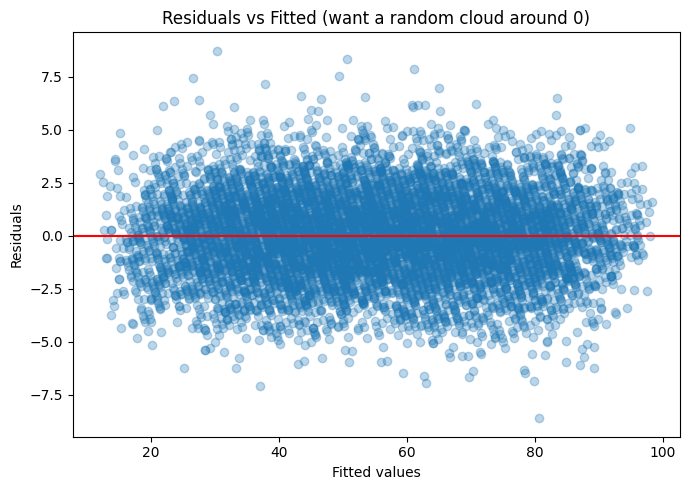

In [16]:
# --------------------------------------------------
# 5. CHECKING ASSUMPTIONS (use statsmodels on the training data)
# --------------------------------------------------

X_train_sm = sm.add_constant(X_train)  # statsmodels needs the intercept column

ols = sm.OLS(y_train, X_train_sm).fit()

print("\n", ols.summary())  # coefficients, p-values, R2, etc.

fitted = ols.fittedvalues
resid = ols.resid

# 5a. Linearity & Homoscedasticity: residuals vs fitted
plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("02_residuals.png")
plt.show()


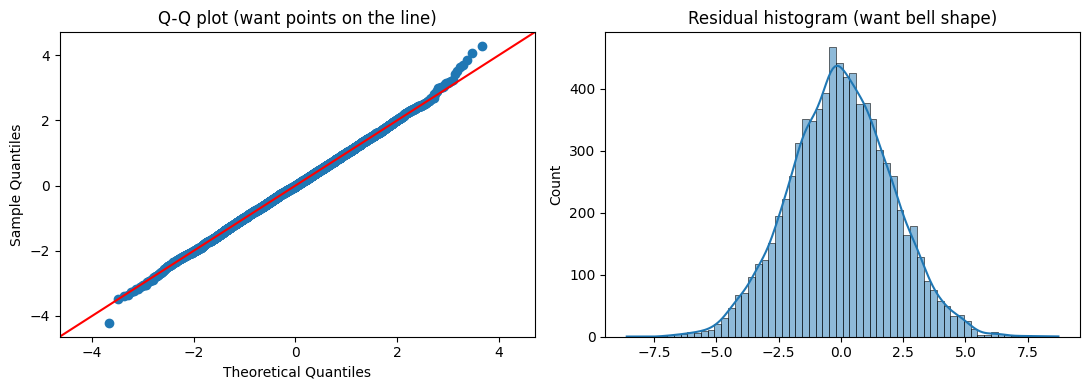

Breusch-Pagan p-value: 0.2396245087908097
Durbin-Watson: 2.0331060225040156


In [17]:
# 5b. Normality of residuals: Q-Q plot + histogram
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")

sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")

plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

# 5c. Homoscedasticity test: Breusch-Pagan (p > 0.05 => constant variance OK)
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)

print("Breusch-Pagan p-value:", bp_p)

# 5d. Independence of errors: Durbin-Watson
# (~2 means no autocorrelation)
print("Durbin-Watson:", durbin_watson(resid))




VIF:
                             feature       VIF
1                     Hours Studied  1.000387
2                   Previous Scores  1.000243
3        Extracurricular Activities  1.000428
4                       Sleep Hours  1.000461
5  Sample Question Papers Practiced  1.000320


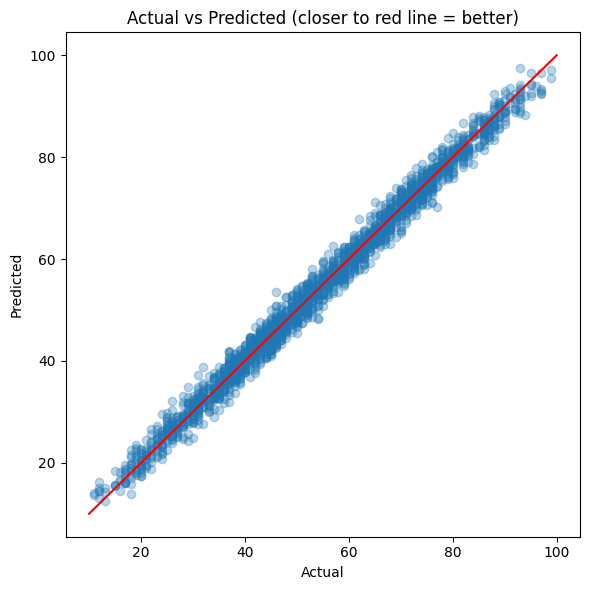

In [18]:
# 5e. Multicollinearity: VIF (want < 5, worry above 10)

vif = pd.DataFrame({
    "feature": X_train_sm.columns,
    "VIF": [
        variance_inflation_factor(X_train_sm.values, i)
        for i in range(X_train_sm.shape[1])
    ]
})

print("\nVIF:\n", vif[vif["feature"] != "const"])

# --------------------------------------------------
# 6. FINAL: Actual vs Predicted
# --------------------------------------------------

plt.figure(figsize=(6, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color="red"
)  # perfect prediction line

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")

plt.tight_layout()
plt.savefig("05_actual_vs_pred.png")
plt.show()